# Bloque 1 · Precio de compra de vivienda desde 2000

Una medida principal: **tasación de vivienda libre en €/m²**. España, comunidades y provincias: **2000–2025**. IPC: **2002–2025**. Municipios seleccionados: **2005–2025**.

La tasación no equivale al precio anunciado ni al precio efectivo de una transacción.

In [2]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data/snapshots/block01").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from spain_housing.prices_analysis import load_purchase_data, run_analysis, series_for

values, municipal, cpi, governments = load_purchase_data(ROOT)
purchase = series_for(values, level="national")
FIGURES = ROOT / "reports/figures/block01"
TABLES = ROOT / "reports/tables/block01"
def show(*names):
    for name in names:
        display(Image(filename=str(FIGURES / f"{name}.png")))


## 1. Evolución nacional

El código muestra directamente la serie utilizada.

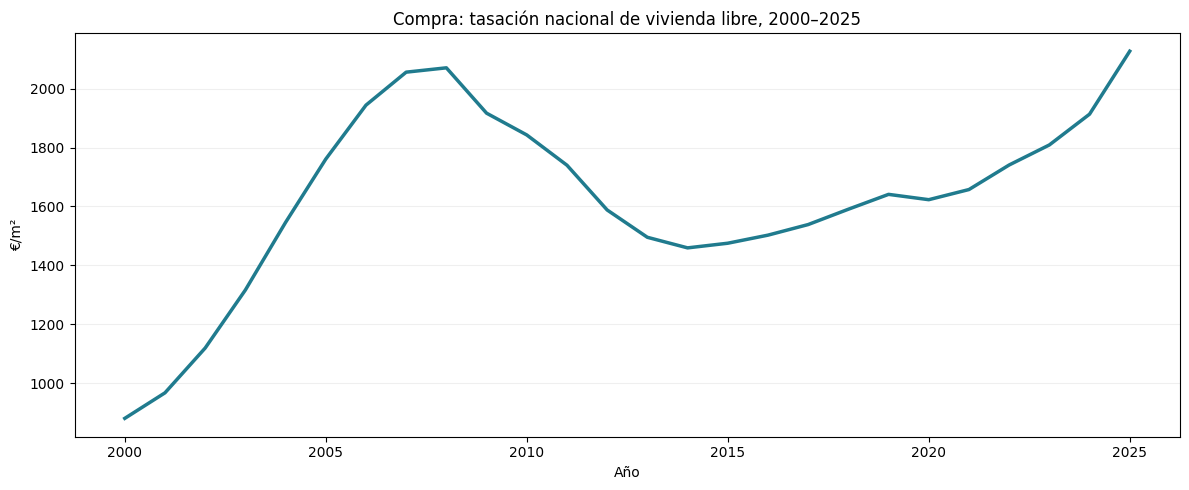

In [4]:
# Observaciones originales de tasación: una sola medida, sin encadenar otras fuentes.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(purchase.index, purchase, color="#207b8e", linewidth=2.5)
ax.set(title="Compra: tasación nacional de vivienda libre, 2000–2025", ylabel="€/m²", xlabel="Año")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)


## 2. Compra frente a los precios generales

Comparamos cuánto ha subido la compra respecto a los precios generales, medidos por el IPC. El IPC no indica si los ingresos han crecido al mismo ritmo.

,Cambio acumulado (%)
Compra: tasación €/m²,90.11
Precios generales (IPC),66.57


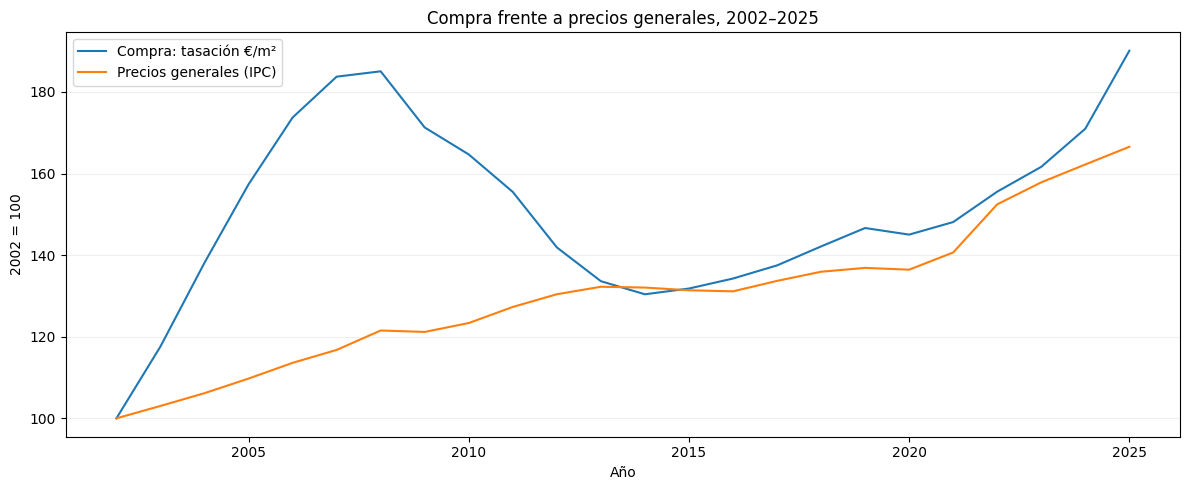

In [6]:
# La comparación empieza donde hay datos de ambas series: 2002.
years = sorted(set(purchase.index) & set(cpi.index))
base = years[0]
comparison = pd.DataFrame({
    "Compra: tasación €/m²": purchase.loc[years] / purchase.loc[base] * 100,
    "Precios generales (IPC)": cpi.loc[years] / cpi.loc[base] * 100,
})
display((comparison.iloc[-1] - 100).to_frame("Cambio acumulado (%)").round(2))
fig, ax = plt.subplots(figsize=(12, 5))
comparison.plot(ax=ax)
ax.set(title=f"Compra frente a precios generales, {years[0]}–{years[-1]}", ylabel=f"{base} = 100", xlabel="Año")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)


## 3. Reproducir las figuras y tablas

Un único generador usa las mismas definiciones para todo el bloque. Los snapshots no se descargan.

In [8]:
figures, findings = run_analysis(ROOT)
print(f"{len(figures)} figuras de compra generadas.")
display(pd.read_csv(TABLES / "national_purchase_history.csv").round(2))

13 figuras de compra generadas.


,code,name,first_year,last_year,observed_years,missing_years,first_value,last_value,nominal_change_pct,real_first_year,real_last_year,real_change_pct,precrisis_peak_year,precrisis_peak_value,postcrisis_trough_year,postcrisis_trough_value,peak_to_trough_pct,trough_to_latest_pct,peak_to_latest_pct
0,0,España,2000,2025,26,0,880.22,2127.57,141.71,2002,2025,14.14,2008,2071.07,2014,1459.4,-29.53,45.78,2.73


## 4. Cambios anuales y ciclo

Extremos: máximo 2000–2008 y mínimo 2009–2015.

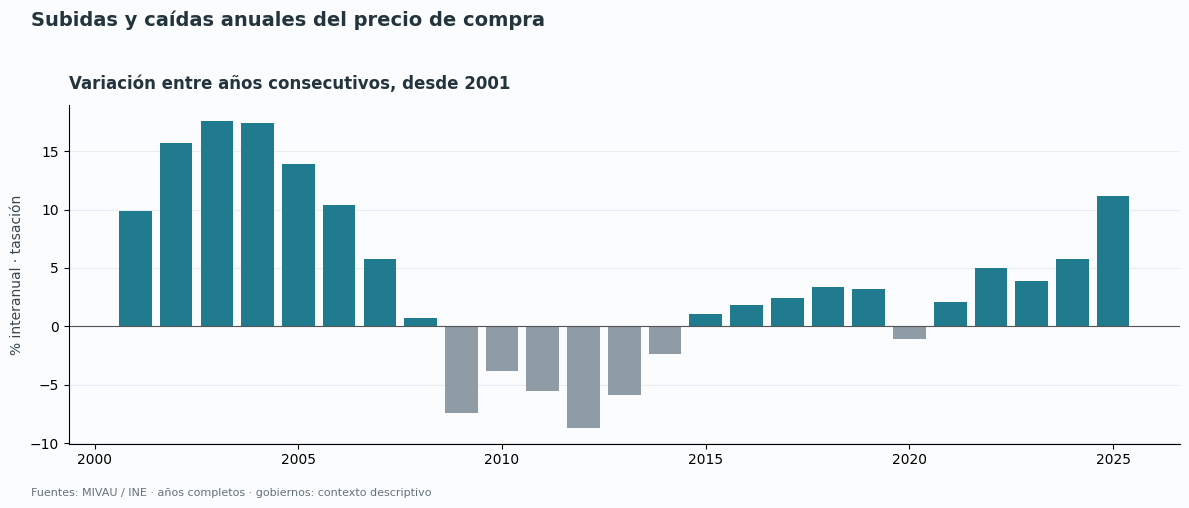

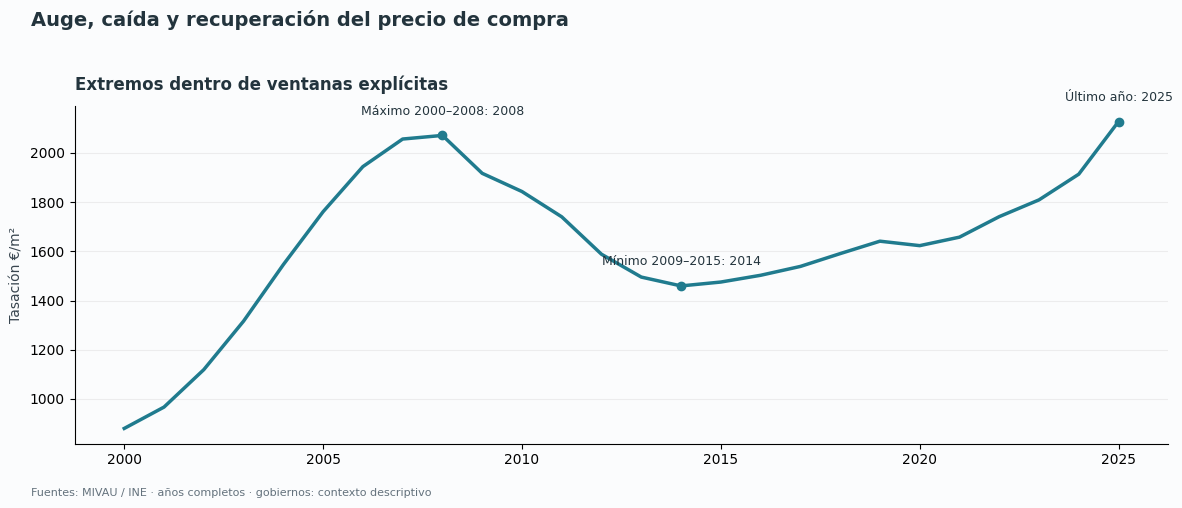

In [10]:
show("04_annual_changes", "05_purchase_cycle")

## 5. Comunidades y provincias

Nivel 2025 y cambio 2000–2025 con extremos fijos. Las tablas mantienen años ausentes y cobertura.

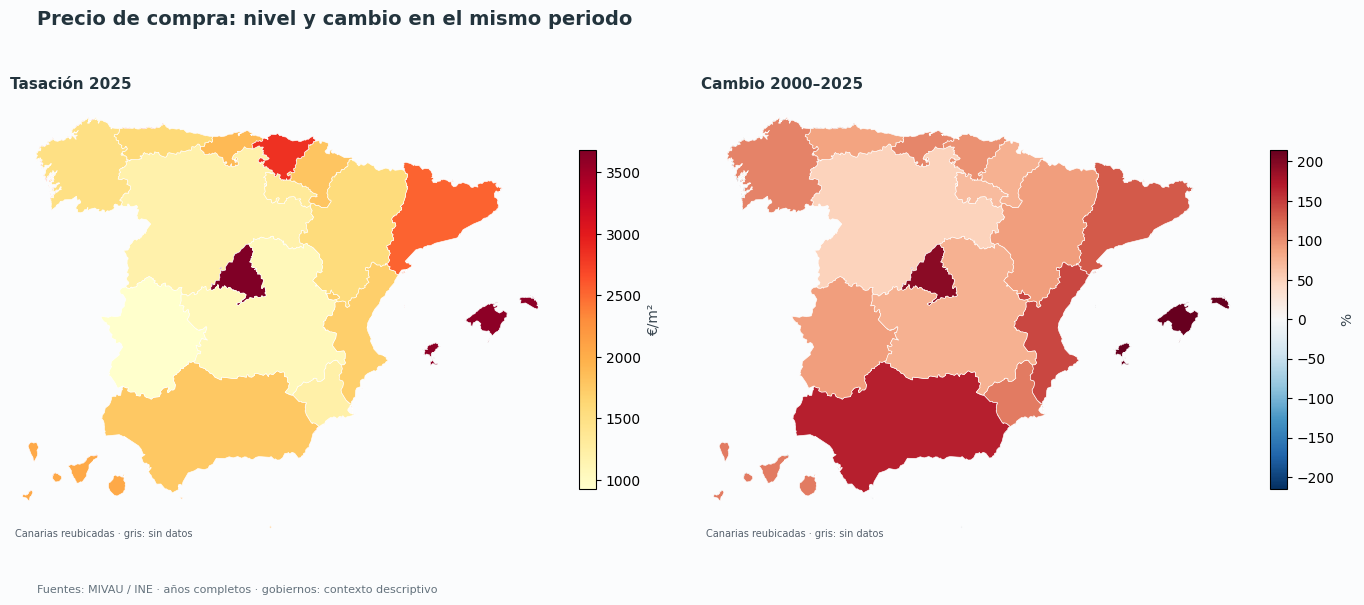

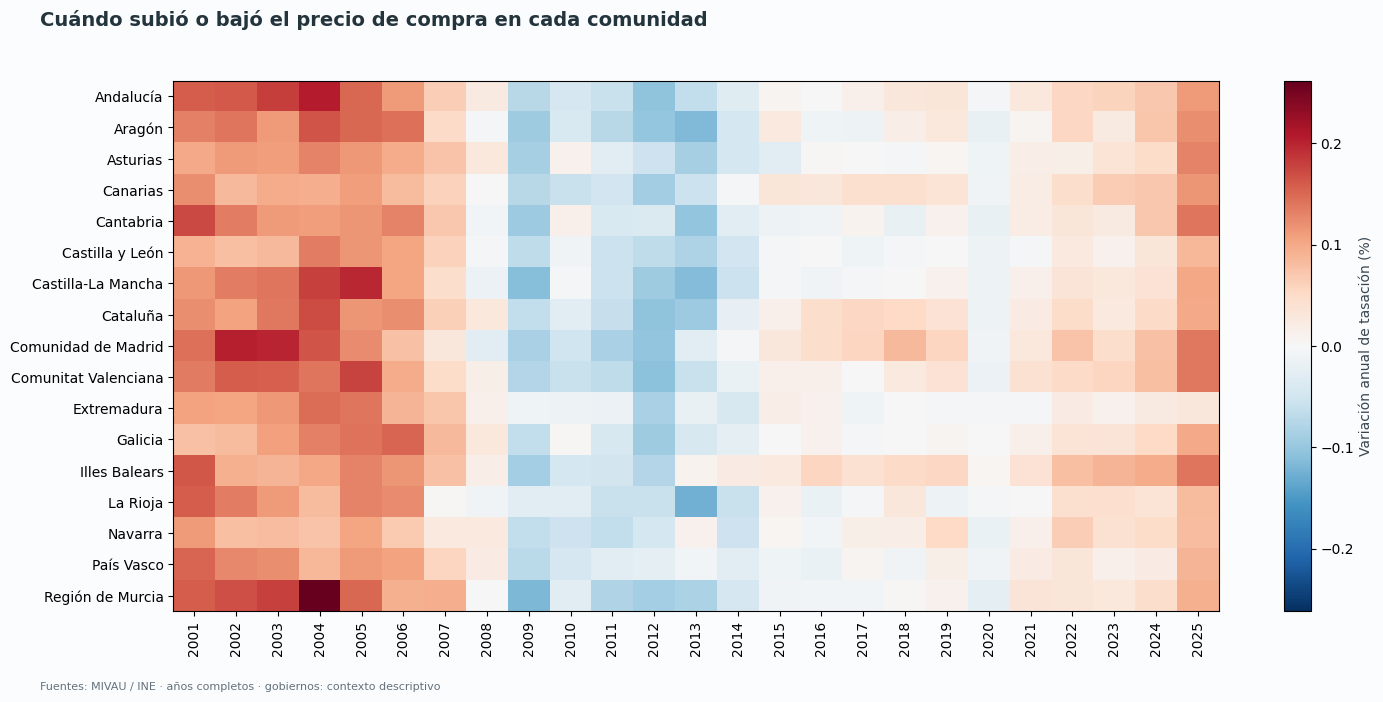

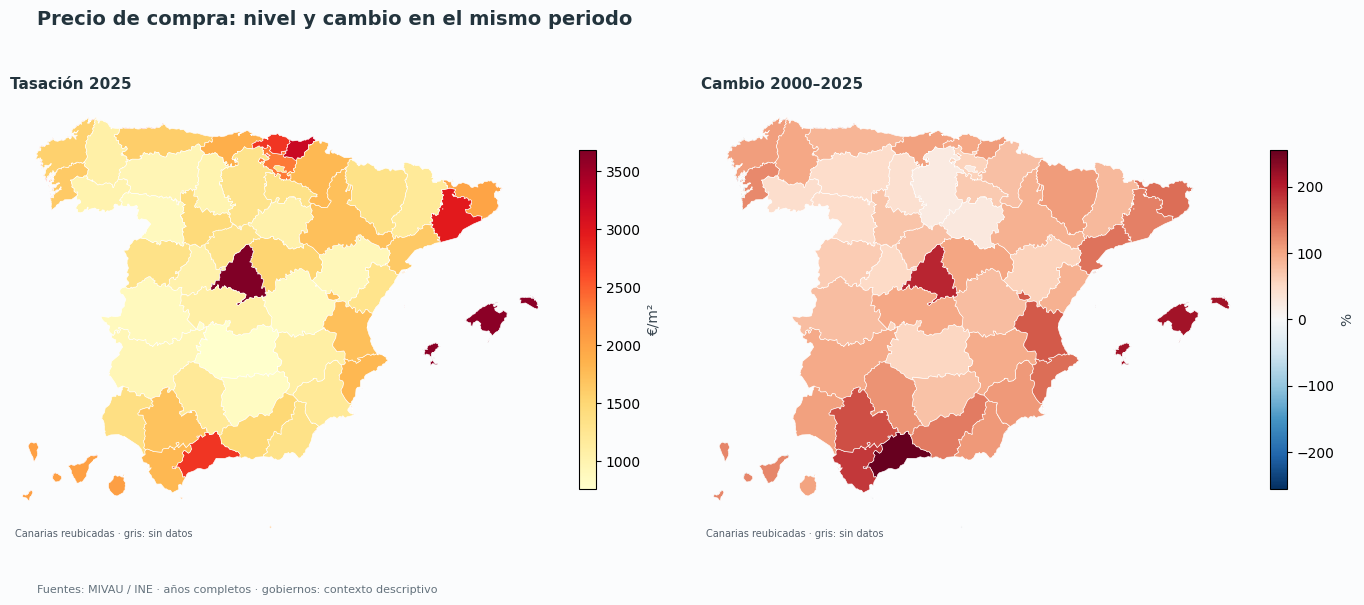

In [12]:
show("07_regional_maps", "08_regional_heatmap", "12_provincial_maps")

## 6. Municipios y perfiles

30 casos desde 2005; muestras fijas, medias no ponderadas. La selección no representa todos los municipios españoles.

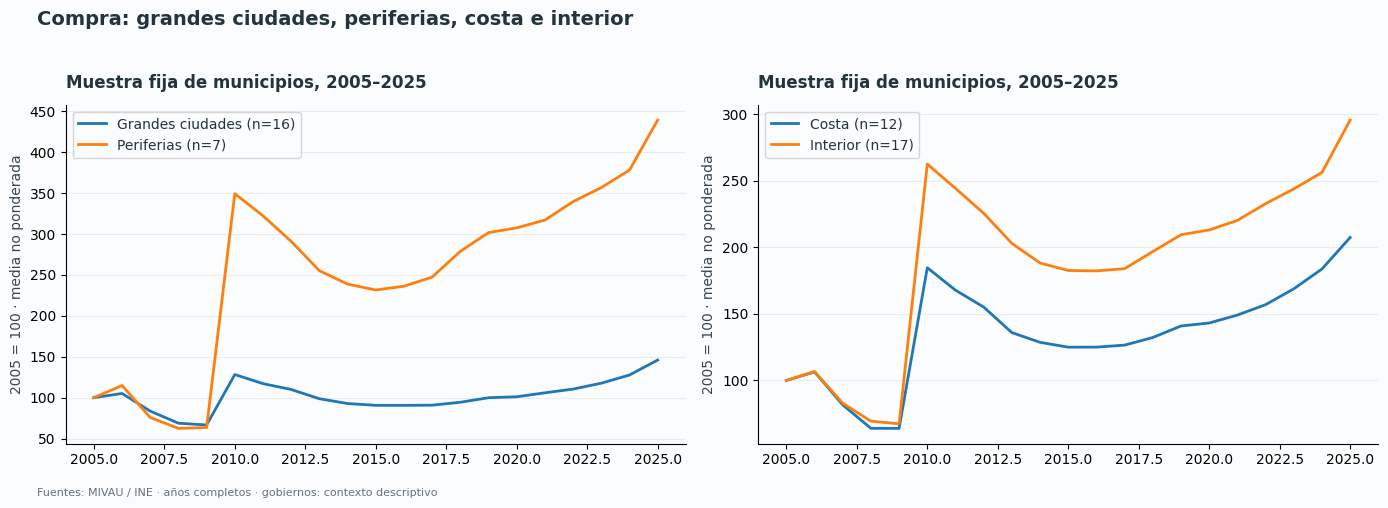

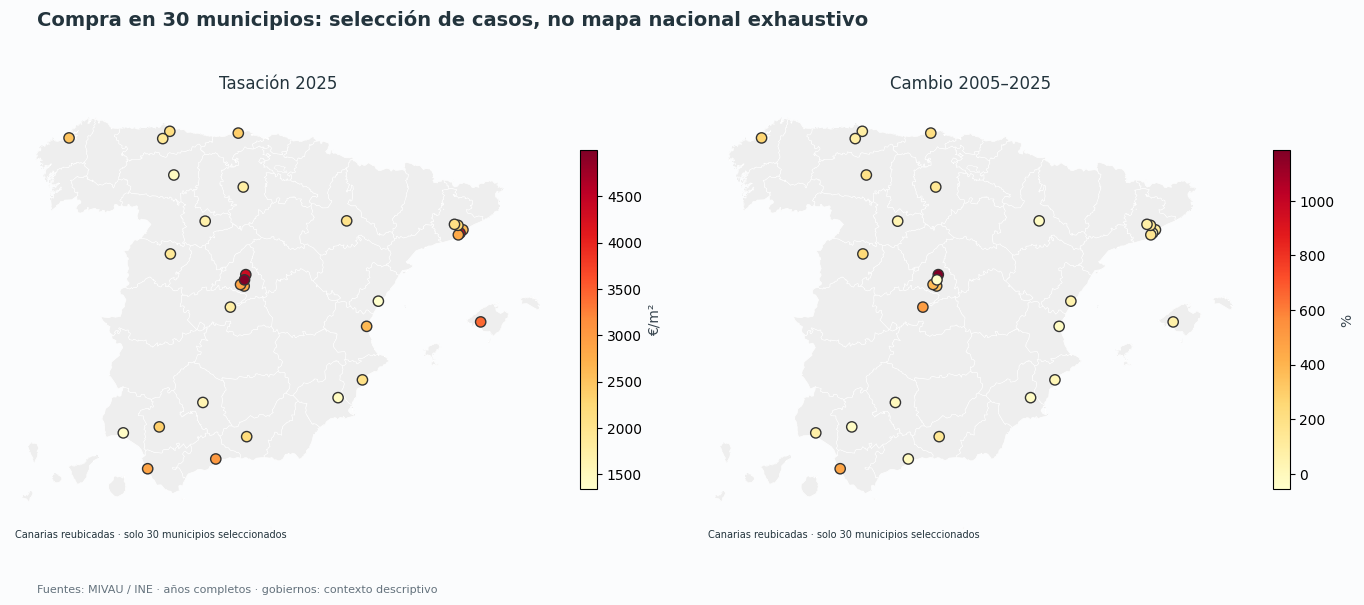

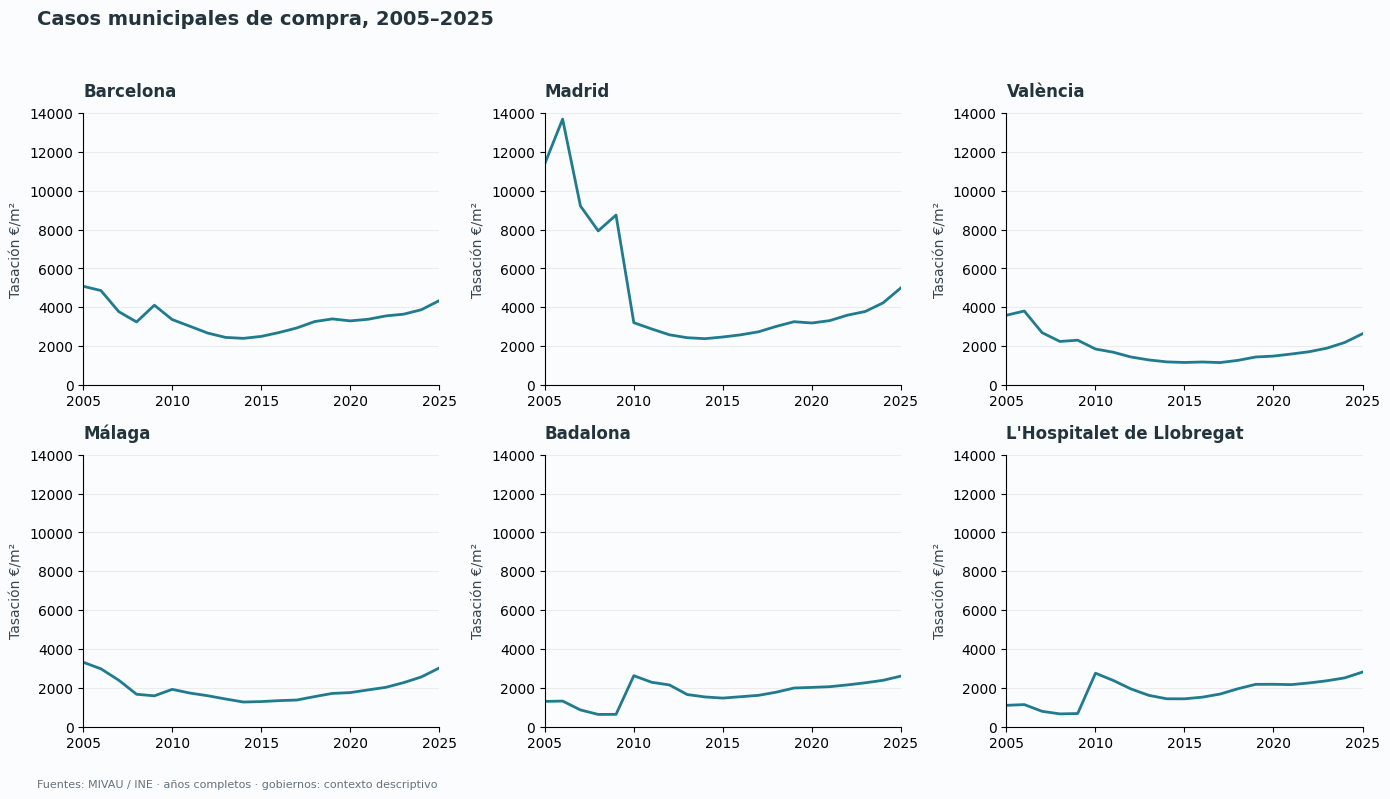

,code,name,year,value,growth_pct,urban_category,coastal_category
0,3014,Alacant/Alicante,2025,2069.35,21.03,large_city,coastal
1,7040,Palma,2025,3424.15,68.10,large_city,coastal
2,8015,Badalona,2025,2603.70,100.17,periphery,coastal
3,8019,Barcelona,2025,4339.92,-14.61,large_city,coastal
4,8101,L'Hospitalet de Llobregat,2025,2812.72,155.88,periphery,unclassified
5,8187,Sabadell,2025,2254.82,144.16,periphery,inland
6,8279,Terrassa,2025,2099.10,75.07,periphery,inland
7,9059,Burgos,2025,1755.25,146.01,selected_city,inland
8,11012,Cádiz,2025,2885.02,466.25,selected_city,coastal
9,12040,Castelló de la Plana/Castellón de la Plana,2025,1338.72,50.80,selected_city,coastal


In [14]:
show("06_territorial_profiles", "13_municipal_maps", "15_municipal_cases")
display(pd.read_csv(TABLES / "selected_municipalities.csv").round(2))

## 7. Gobiernos como contexto temporal

Franjas de presidencias, sin atribución causal. Los periodos observados usan años completos dentro de cada mandato; no son un ranking de partidos.

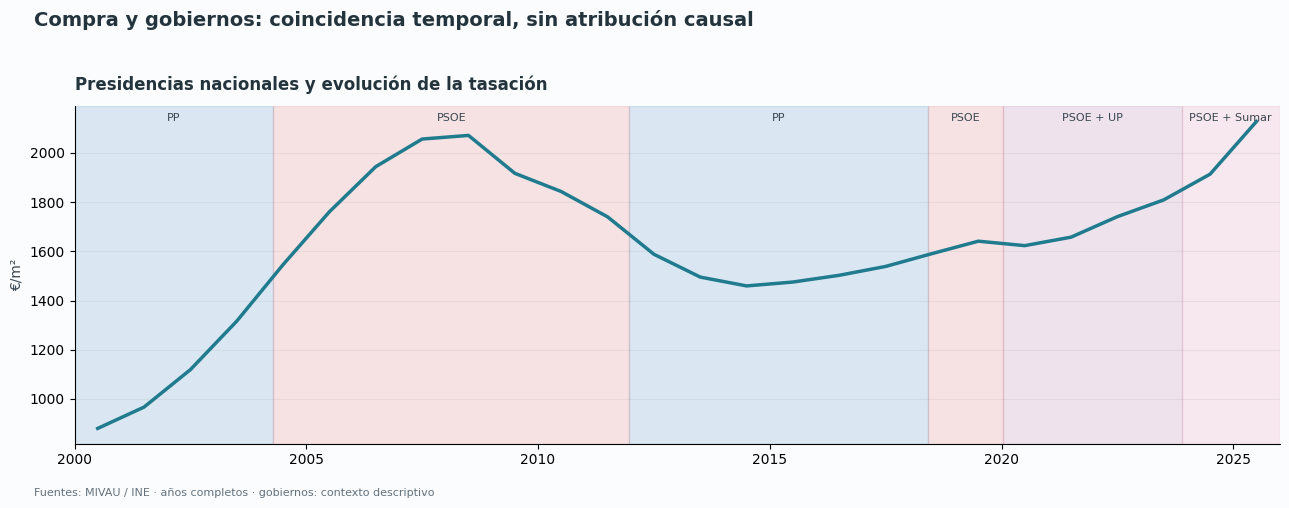

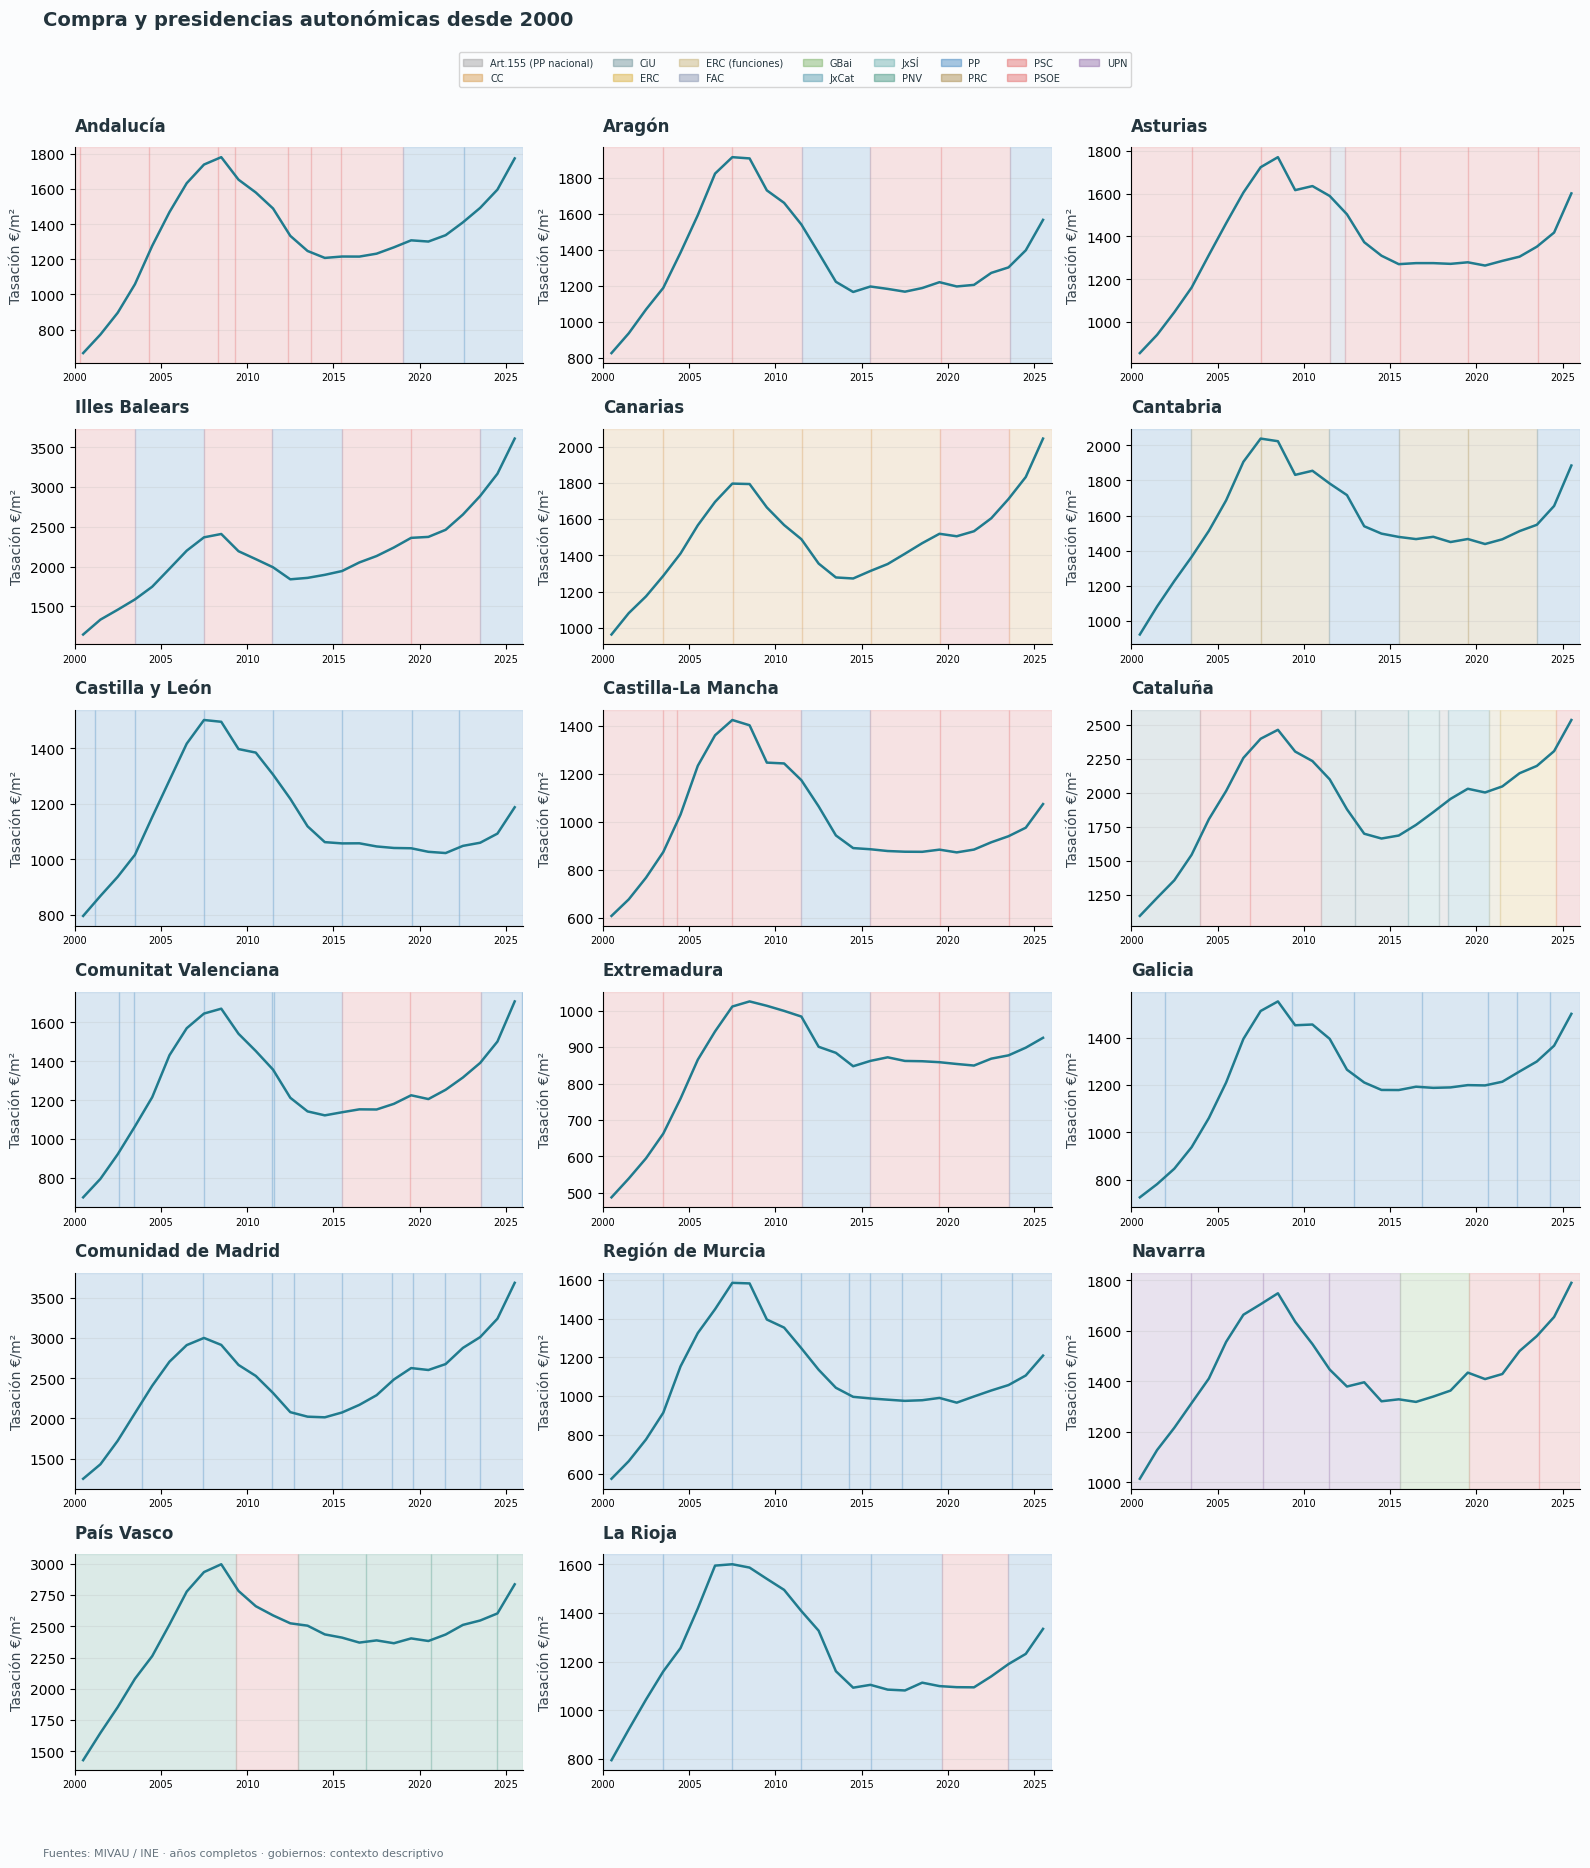

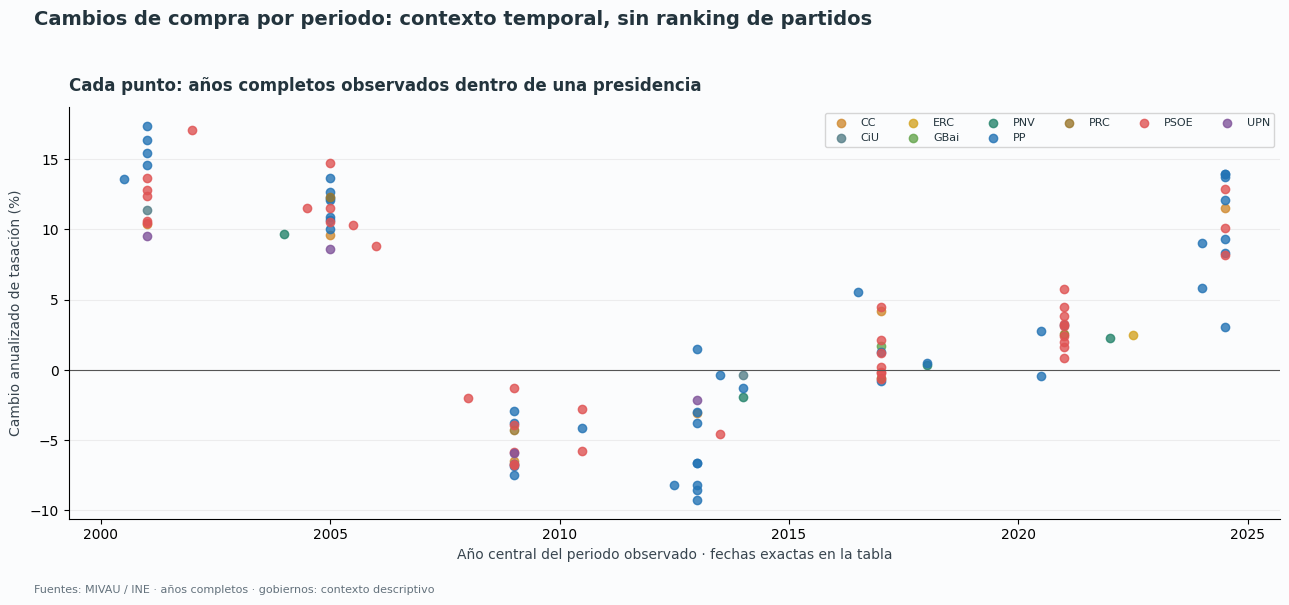

In [16]:
show("02_national_governments", "09_regional_governments_purchase", "10_mandate_comparison")